# Сравнение алгоритмов SMS — задание №8

По умолчанию показаны сохранённые результаты. RUN_EXPERIMENT=True полностью повторяет эксперимент и перезаписывает артефакты. Test используется один раз после выбора. Ручные признаки одинаковы во всех вариантах. Подробнее: docs/08_sms_model_comparison.md.

In [1]:
from pathlib import Path
import os, sys, json
root = Path.cwd()
if not (root / 'ml').is_dir():
    root = root.parent
os.chdir(root)
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from ml.compare_sms import run_experiment, ARTIFACTS
RUN_EXPERIMENT = False
meta = run_experiment() if RUN_EXPERIMENT else json.loads((ARTIFACTS / 'sms_model_meta.json').read_text(encoding='utf-8'))

In [2]:
import pandas as pd
rows=[]
for r in meta['comparison']:
    rows.append(dict(algorithm=r['algorithm'], **r['validation_metrics'], threshold=r['threshold'], training_seconds=r['training_seconds'], prediction_ms=r['prediction_ms']))
pd.DataFrame(rows).drop(columns='confusion_matrix')

,algorithm,accuracy,precision,recall,f1,f2,roc_auc,pr_auc,threshold,training_seconds,prediction_ms
0,MultinomialNB,0.977922,0.857143,0.978261,0.913706,0.951374,0.993299,0.986814,0.076758,0.861242,5.260380
1,LogisticRegression,0.977922,0.857143,0.978261,0.913706,0.951374,0.997772,0.989324,0.147656,10.183735,7.366547
2,LinearSVC,0.977922,0.857143,0.978261,0.913706,0.951374,0.997964,0.990202,0.084335,11.283920,34.162647


In [3]:
pd.DataFrame(meta['experiments'])

,algorithm,include_chars,stop_words,parameter,cv_f2
0,MultinomialNB,False,None,{'classifier__alpha': 0.1},0.939458
1,MultinomialNB,False,None,{'classifier__alpha': 0.5},0.663616
2,MultinomialNB,False,None,{'classifier__alpha': 1.0},0.199356
3,MultinomialNB,False,english,{'classifier__alpha': 0.1},0.928498
4,MultinomialNB,False,english,{'classifier__alpha': 0.5},0.767913
5,MultinomialNB,False,english,{'classifier__alpha': 1.0},0.389452
6,MultinomialNB,True,None,{'classifier__alpha': 0.1},0.936865
7,MultinomialNB,True,None,{'classifier__alpha': 0.5},0.174936
8,MultinomialNB,True,None,{'classifier__alpha': 1.0},0.000000
9,MultinomialNB,True,english,{'classifier__alpha': 0.1},0.933287


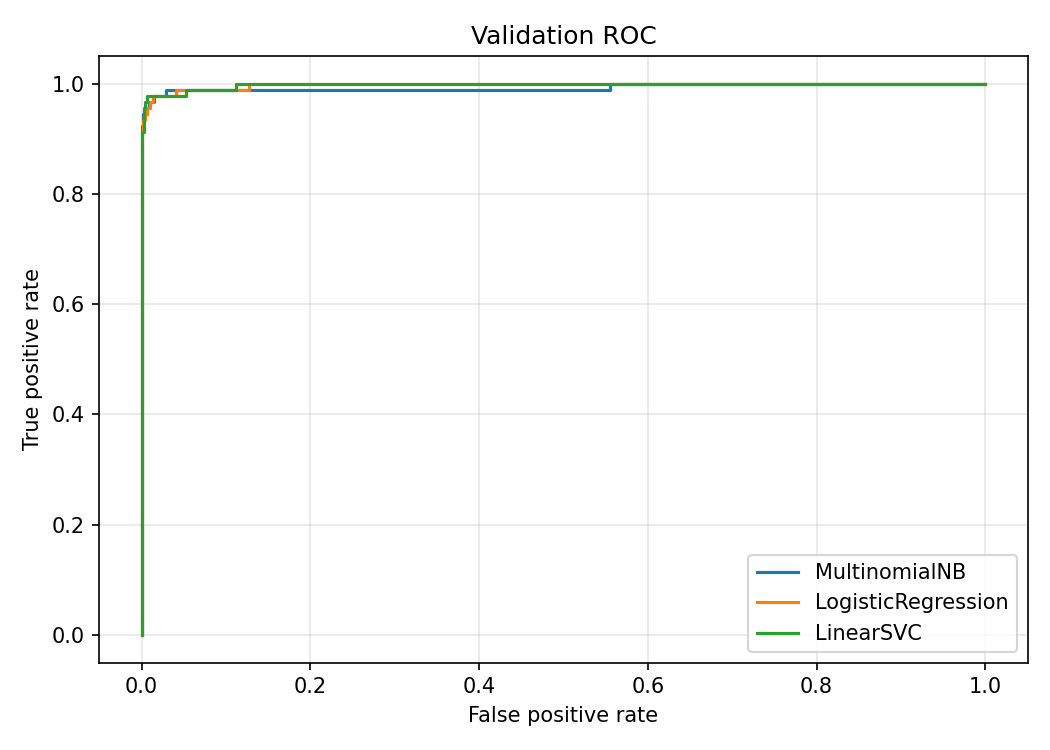

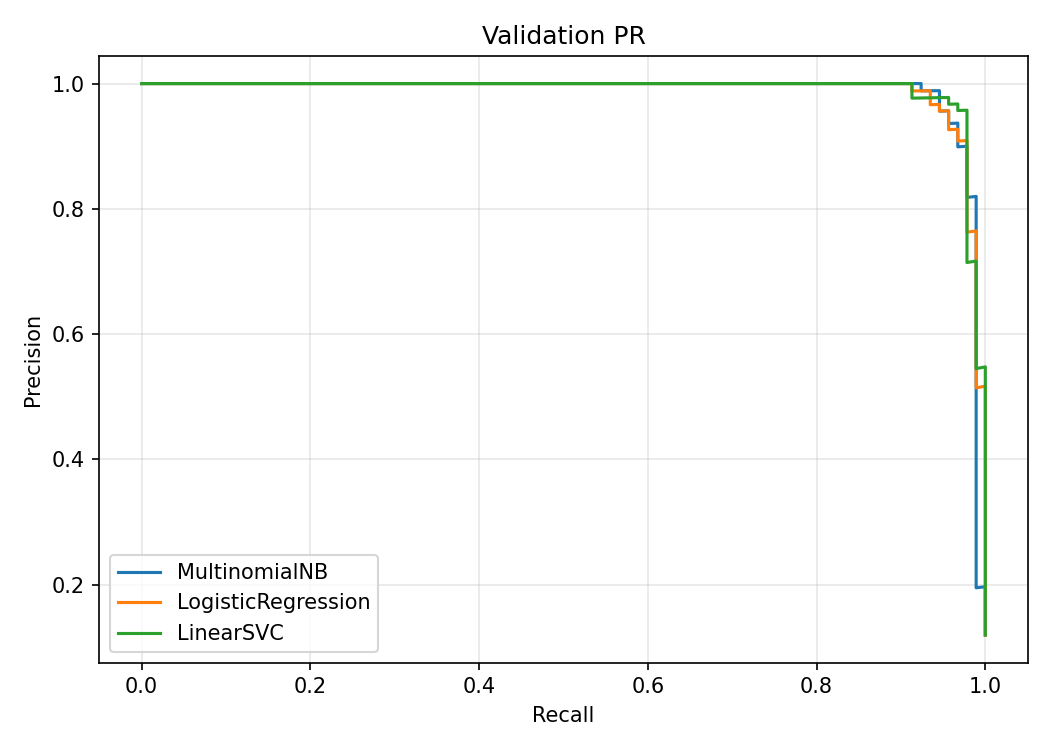

In [4]:
from IPython.display import display, Image
for kind in ('roc', 'pr'):
    display(Image(filename=str(root / 'docs' / f'08_{kind}.png')))

In [5]:
display(meta['algorithm'], meta['threshold'], meta['test_metrics'], meta['language_metrics'])

'MultinomialNB'

0.07675798320542866

{'accuracy': 0.9494163424124513,
 'precision': 0.7288135593220338,
 'recall': 0.9247311827956989,
 'f1': 0.8151658767772512,
 'f2': 0.8775510204081632,
 'roc_auc': 0.9790655628508896,
 'pr_auc': 0.9506300262113972,
 'confusion_matrix': [[646, 32], [7, 86]]}

{'ru': {'accuracy': 0.28,
  'precision': 0.3472222222222222,
  'recall': 0.5,
  'f1': 0.4098360655737705,
  'f2': 0.45955882352941174,
  'roc_auc': 0.5002,
  'pr_auc': 0.7141286699745533,
  'confusion_matrix': [[3, 47], [25, 25]]},
 'kk': {'accuracy': 0.26,
  'precision': 0.34210526315789475,
  'recall': 0.52,
  'f1': 0.4126984126984127,
  'f2': 0.47101449275362317,
  'roc_auc': 0.52,
  'pr_auc': 0.7292773950588405,
  'confusion_matrix': [[0, 25], [12, 13]]}}

Тестовые метрики получены **до** переобучения на Train + Validation. PR-AUC = average_precision_score (AP). Искусственные ru/kk не участвуют в обучении и настройке. Модель обучена на английском UCI; полноценная поддержка ru/kk не подтверждена.